<div align="center">

# Q-RESILIENCE
### Quantum-Enhanced Network Reliability Estimation

**Estimating source–target disconnection under probabilistic edge failures**

*A Qiskit study of classical reliability calculations, quantum amplitude estimation, oracle construction, and circuit-resource costs.*

</div>

---

## Overview

Q-Resilience estimates the probability that a specified source and target become disconnected when network edges fail independently. The workflow represents the network as a graph, calculates a classical reference probability, prepares the corresponding failure distribution on a quantum register, and marks disconnected configurations. Iterative Quantum Amplitude Estimation (IQAE) is then used to estimate the probability of the marked subspace.

The results are compared with exact enumeration and Monte Carlo sampling. The notebook also examines estimation error, sensitivity to depolarizing noise, and the resources required by the circuit constructions.

> **Scope.** Exact enumeration serves as the reference for the small networks used in validation. The explicit minterm oracle and the reachability-based oracle are both examined; their different circuit costs are important when considering larger graphs.

## Quantities examined

| Area | Quantities |
|---|---|
| Reliability | Exact disconnection probability, Monte Carlo estimate, IQAE estimate |
| Estimation quality | Absolute error and IQAE confidence interval |
| Query cost | State-preparation calls and classical sample count |
| Circuit resources | Qubit count, gate count, and circuit depth |
| Noise | Estimated disconnection probability over depolarizing rates and Grover iterations |
| Scaling | Qubit, gate, and depth growth on 2D grid graphs |

For additive error $\varepsilon$, classical Monte Carlo has sample complexity proportional to $O(\varepsilon^{-2})$. Ideal amplitude estimation has oracle-query complexity proportional to $O(\varepsilon^{-1})$, with additional dependence on the desired confidence. These query bounds do not by themselves describe wall-clock runtime: oracle construction, circuit depth, and hardware noise also matter.

---

**Notebook layout:** The sections below follow the execution order. Each explanation is placed immediately before the code it describes.

## Experimental setup and comparisons

The notebook uses exact enumeration as a reference on small graphs and compares it with Monte Carlo sampling and IQAE. Four aspects of the implementation are examined:

1. **Estimation cost:** the number of state-preparation calls is used when comparing the quantum and classical estimates.
2. **Noise behaviour:** circuits are decomposed into the gate basis used by the noise model before simulation; circuit depth and CX count are reported alongside the estimates.
3. **Oracle construction:** the explicit minterm oracle is compared with a reachability-based compiler that avoids enumerating every failure mask during compilation.
4. **Network input and scaling:** a network can be specified in the configuration or loaded from CSV, and resource counts are measured on a family of 2D grid graphs.

The figures should be read as results for the stated simulator, parameter ranges, and graph sizes. They are not hardware benchmarks or a claim of a general end-to-end quantum speed-up.

> **Noise plot note.** A curve close to its fully mixed reference value may carry little information about the original probability. Interpret the noise results together with the reference lines, circuit depth, and CX counts.

## Cell 0 — Environment and dependencies

Install the graph, numerical, plotting, and quantum-computing packages required by the notebook. Run this cell in a fresh Colab runtime. If the installation changes the active Qiskit environment, restart the runtime before continuing.

> **Reproducibility.** Package version constraints keep the Qiskit components within the API versions used by this implementation.

In [1]:
# %% [Cell 0] — Install dependencies (run once, then Kernel → Restart)
%pip install -q "qiskit>=1.0,<3.0" "qiskit-algorithms>=0.4.0" \
                  "qiskit-aer>=0.14.0" networkx numpy matplotlib

Note: you may need to restart the kernel to use updated packages.


## Cell 1 — Input and configuration

Set the network topology, edge-failure probabilities, source and target nodes, IQAE settings, Monte Carlo budget, plotting ranges, and output options in this section. The remaining cells use these configuration values.

For independent edge failures $X_e\sim\mathrm{Bernoulli}(p_e)$, the probability of source–target disconnection is

$$
P_{\mathrm{disc}}
=\Pr\!\left(s\not\leftrightarrow t\right)
=\sum_{x\in\mathcal{D}}\prod_{e\in E}
p_e^{x_e}(1-p_e)^{1-x_e},
$$

where $\mathcal{D}$ contains the edge-failure bitstrings for which $s$ and $t$ are disconnected.

> **Network input.** Define the graph with `GRAPH_EDGES` and `FAILURE_PROBS`, or provide a CSV file/text through `NETWORK_CSV` with columns `u`, `v`, and `p_fail`. Leaving `NETWORK_CSV = None` uses the values defined in the configuration.

In [2]:
# %% [Cell 1] — INPUT & CONFIGURATION LAYER
# =====================================================================
# Everything a user would ever want to tune lives in this cell.
# Downstream cells reference these names; no numeric constants are
# hardcoded anywhere else in the notebook.
# =====================================================================

# ---------------------------------------------------------------------
# 1. NETWORK DEFINITION
# ---------------------------------------------------------------------
GRAPH_EDGES = [
    ("s", "a"),
    ("a", "t"),
    ("s", "b"),
    ("b", "t"),
]

FAILURE_PROBS = {
    ("s", "a"): 0.10,
    ("a", "t"): 0.15,
    ("s", "b"): 0.20,
    ("b", "t"): 0.10,
}

SOURCE = "s"
TARGET = "t"

# ---------------------------------------------------------------------
# 1b. OPTIONAL: load the network from a CSV instead.
#     Two ways to define the network -- both keep working:
#       (A) leave NETWORK_CSV = None  -> the notebook uses GRAPH_EDGES / FAILURE_PROBS above (edit by hand)
#       (B) set NETWORK_CSV           -> a file path (e.g. "my_network.csv") or the raw CSV text.
#           Columns: u, v, p_fail   (one row per link, p_fail strictly between 0 and 1)
#           CSV_SOURCE / CSV_TARGET name the two nodes whose connection you care about.
# ---------------------------------------------------------------------
NETWORK_CSV = None
CSV_SOURCE  = "s"
CSV_TARGET  = "t"

# ---------------------------------------------------------------------
# 2. ORACLE / FAILURE-MINTERM THRESHOLDS
# ---------------------------------------------------------------------
# The v0 cut-set oracle enumerates disconnected edge-failure minterms.
# MINTERM_PROB_FLOOR > 0  trims negligible-probability minterms from
# the oracle only. Ground-truth `exact_enumeration` still uses the full
# set. Default 0.0 keeps oracle ≡ exact.
MINTERM_PROB_FLOOR = 0.0
# Hard cap on marked minterms (for scaling demos). None = unlimited.
MAX_MINTERMS = None

# ---------------------------------------------------------------------
# 3. IQAE SETTINGS (qiskit-algorithms ≥ 0.3 API)
# ---------------------------------------------------------------------
IQAE_EPSILON = 0.02     # epsilon_target (precision)
IQAE_ALPHA   = 0.05     # 1 - confidence level
IQAE_SHOTS   = 100      # A smaller per-round shot budget allows the precision sweep to produce more distinct estimates.
IQAE_SEED    = 7

# ---------------------------------------------------------------------
# 4. CLASSICAL MONTE CARLO BASELINE
# ---------------------------------------------------------------------
MC_NUM_SAMPLES = 20_000
MC_SEED        = 7

# ---------------------------------------------------------------------
# 5. PLOT 1 — Error vs Oracle Calls
# ---------------------------------------------------------------------
PLOT1_MC_SAMPLE_COUNTS = [1_000, 4_000, 16_000, 64_000, 256_000]
PLOT1_MC_TRIALS        = 10
PLOT1_IQAE_EPS_GRID    = [0.02, 0.01, 0.005, 0.0025, 0.00125, 0.000625]   # Halve the target precision at each step.
PLOT1_IQAE_TRIALS      = 3      # Number of independent seeds used for each precision target.
PLOT1_ERROR_FLOOR      = 1e-6
PLOT1_QUERY_FLOOR      = 1.0

# ---------------------------------------------------------------------
# 6. PLOT 2 — Noise vs Circuit Depth
# ---------------------------------------------------------------------
PLOT2_NOISE_RATES      = [0.0, 1e-4, 3e-4, 1e-3, 3e-3, 1e-2]   # Depolarizing probabilities used in the noise sweep.
PLOT2_K_ITERS          = [0, 1, 2]
PLOT2_SHOTS            = 4096
PLOT2_SEED             = 42
PLOT2_1Q_GATES         = ["u1", "u2", "u3", "rx", "ry", "rz", "x", "sx", "h"]
PLOT2_2Q_GATES         = ["cx", "cz", "mcx"]
PLOT2_2Q_NOISE_SCALE   = 2.0
PLOT2_2Q_NOISE_CAP     = 0.99

# ---------------------------------------------------------------------
# 7. PLOT 3 — Resource Scaling on 2D Grids
# ---------------------------------------------------------------------
PLOT3_GRID_SPECS       = [(2, 2), (2, 3), (2, 4), (3, 3)]
PLOT3_EDGE_PROB        = 0.1
PLOT3_QUBIT_REF_SLOPE  = 2.0

# ---------------------------------------------------------------------
# 8. PLOT STYLING + OUTPUT
# ---------------------------------------------------------------------
PLOT_DPI        = 110
PLOT_SAVE_DPI   = 150
PLOT_FIGSIZE    = (9, 6)

SAVE_FIG1_PATH  = "qresilience_error_vs_oracle.png"
SAVE_FIG2_PATH  = "qresilience_noise_vs_depth.png"
SAVE_FIG3_PATH  = "qresilience_resource_scaling.png"
OUTPUT_DIR      = None      # e.g. "./figures" — None keeps files in cwd

## Cell 2 — Imports, graph construction, and plotting defaults

Import the scientific Python and Qiskit components used in the analysis. The graph is built from the configuration, output paths are resolved, and shared Matplotlib settings are applied here.

> The plotting defaults keep typography, labels, gridlines, and exported figure quality consistent across the notebook.

In [3]:
# %% [Cell 2] — Imports + network build + global plot styling
from __future__ import annotations

import math
import os
import time
from dataclasses import dataclass
from typing import Mapping, Sequence

import networkx as nx
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import LogLocator, NullFormatter

from qiskit import QuantumCircuit, transpile

try:
    from qiskit.primitives import StatevectorSampler
except ImportError:                                        # pragma: no cover
    from qiskit_aer.primitives import Sampler as StatevectorSampler

try:
    from qiskit_algorithms import EstimationProblem, IterativeAmplitudeEstimation
except ImportError:                                        # pragma: no cover
    from qiskit.algorithms import EstimationProblem, IterativeAmplitudeEstimation

Edge = tuple[object, object]

# --- Matplotlib styling driven by config -----------------------------
plt.rcParams.update({
    "figure.dpi": PLOT_DPI,
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "axes.grid": True,
    "grid.alpha": 0.25,
    "grid.linestyle": "--",
    "grid.linewidth": 0.8,
    "font.size": 11,
    "axes.titlesize": 13,
    "axes.labelsize": 12,
    "legend.frameon": False,
    "legend.fontsize": 10,
})

# --- Build the canonical graph from config ---------------------------
NETWORK = nx.Graph()
NETWORK.add_edges_from(GRAPH_EDGES)

# optional CSV input -- overrides the dictionaries above only when NETWORK_CSV is set
def load_network_csv(csv_input, source, target):
    """Parse a CSV (path or raw text) with columns u, v, p_fail. Returns (edge_list, failure_probs)."""
    import csv as _csv, io as _io
    text = csv_input if "\n" in str(csv_input) else open(csv_input, newline="").read()
    rows = list(_csv.DictReader(_io.StringIO(text)))
    if not rows or not {"u", "v", "p_fail"} <= set(rows[0].keys()):
        raise ValueError("CSV needs the header: u,v,p_fail")
    edges, probs, seen = [], {}, set()
    for line_no, r in enumerate(rows, start=2):
        u, v, p = r["u"].strip(), r["v"].strip(), float(r["p_fail"])
        if u == v:                      raise ValueError(f"line {line_no}: self-loop {u}-{v}")
        if frozenset((u, v)) in seen:   raise ValueError(f"line {line_no}: duplicate link {u}-{v}")
        if not 0.0 < p < 1.0:           raise ValueError(f"line {line_no}: p_fail must be in (0,1), got {p}")
        seen.add(frozenset((u, v))); edges.append((u, v)); probs[(u, v)] = p
    g = nx.Graph(edges)
    if source == target or source not in g or target not in g:
        raise ValueError("CSV_SOURCE / CSV_TARGET must be two different nodes that appear in the CSV")
    if not nx.has_path(g, source, target):
        raise ValueError("source and target are not connected even when every link works")
    return edges, probs

if NETWORK_CSV is not None:
    GRAPH_EDGES, FAILURE_PROBS = load_network_csv(NETWORK_CSV, CSV_SOURCE, CSV_TARGET)
    SOURCE, TARGET = CSV_SOURCE, CSV_TARGET
    NETWORK = nx.Graph()
    NETWORK.add_edges_from(GRAPH_EDGES)
    print(f"[input] network loaded from CSV: {NETWORK.number_of_nodes()} nodes, "
          f"{NETWORK.number_of_edges()} links, {SOURCE} -> {TARGET}")
else:
    print("[input] network taken from GRAPH_EDGES / FAILURE_PROBS in the config cell")

def _resolve_path(name: str) -> str:
    """Honour OUTPUT_DIR from config; fall back to cwd."""
    if OUTPUT_DIR is None:
        return name
    os.makedirs(OUTPUT_DIR, exist_ok=True)
    return os.path.join(OUTPUT_DIR, name)

PATH_FIG1 = _resolve_path(SAVE_FIG1_PATH)
PATH_FIG2 = _resolve_path(SAVE_FIG2_PATH)
PATH_FIG3 = _resolve_path(SAVE_FIG3_PATH)

[input] network taken from GRAPH_EDGES / FAILURE_PROBS in the config cell


## Cell 3 — Classical reference methods

This section defines the connectivity test, enumerates edge-failure configurations, evaluates their probabilities, and implements a Monte Carlo estimate. Exact enumeration provides the reference value for the configured graph.

For a failure mask $x$, independence gives

$$
\Pr(X=x)=\prod_{e\in E}
\begin{cases}
p_e,&x_e=1,\\
1-p_e,&x_e=0.
\end{cases}
$$

Summing over all disconnected masks gives the exact disconnection probability. Monte Carlo estimates the same quantity from $M$ sampled networks:

$$
\widehat P_{\mathrm{MC}}
=\frac{1}{M}\sum_{j=1}^{M}
\mathbf{1}\{s\not\leftrightarrow t\text{ in sample }j\}.
$$

> Exact enumeration is practical for small graphs and provides a reference for assessing the two approximate estimation methods.

In [4]:
# %% [Cell 3] — Classical baselines (exact enumeration + Monte Carlo)
def _canonical_edge(u, v) -> Edge:
    return (u, v) if str(u) <= str(v) else (v, u)

def _ordered_edges(graph: nx.Graph) -> list[Edge]:
    edges = (_canonical_edge(u, v) for u, v in graph.edges())
    return sorted(edges, key=lambda e: (str(e[0]), str(e[1])))

def _failure_probability(failure_probs, edge: Edge) -> float:
    u, v = edge
    if (u, v) in failure_probs:
        p = float(failure_probs[(u, v)])
    elif (v, u) in failure_probs:
        p = float(failure_probs[(v, u)])
    else:
        raise KeyError(f"Missing failure probability for edge {edge!r}.")
    if not 0.0 <= p <= 1.0:
        raise ValueError(f"p for {edge!r} must be in [0, 1], got {p}.")
    return p

def _validate_endpoints(graph, source, target):
    if source not in graph:
        raise ValueError(f"Source {source!r} not in graph.")
    if target not in graph:
        raise ValueError(f"Target {target!r} not in graph.")

def _is_disconnected(graph, edge_list, failed_mask, source, target) -> bool:
    if source == target:
        return False
    adjacency = {node: [] for node in graph.nodes()}
    for i, (u, v) in enumerate(edge_list):
        if not ((failed_mask >> i) & 1):
            adjacency[u].append(v)
            adjacency[v].append(u)
    seen, stack = {source}, [source]
    while stack:
        node = stack.pop()
        if node == target:
            return False
        for nbr in adjacency[node]:
            if nbr not in seen:
                seen.add(nbr)
                stack.append(nbr)
    return True

def disconnected_masks(graph, edge_list, source, target) -> list[int]:
    """Full disconnected-mask set — used by both exact and oracle paths."""
    _validate_endpoints(graph, source, target)
    if source == target:
        return []
    return [
        mask for mask in range(1 << len(edge_list))
        if _is_disconnected(graph, edge_list, mask, source, target)
    ]

def _mask_probability(mask: int, probs: Sequence[float]) -> float:
    """Probability of one edge-failure minterm under independent edges."""
    p = 1.0
    for i, pf in enumerate(probs):
        p *= pf if ((mask >> i) & 1) else (1.0 - pf)
    return p

def exact_enumeration(graph, failure_probs, source, target) -> float:
    """Ground truth: no minterm filtering, no approximation."""
    edges = _ordered_edges(graph)
    probs = [_failure_probability(failure_probs, e) for e in edges]
    masks = disconnected_masks(graph, edges, source, target)
    return float(sum(_mask_probability(m, probs) for m in masks))

def monte_carlo_simulation(
    graph,
    failure_probs,
    source,
    target,
    num_samples: int = MC_NUM_SAMPLES,
    seed: int | None = MC_SEED,
) -> float:
    """Empirical disconnection probability via classical sampling."""
    if num_samples <= 0:
        raise ValueError("num_samples must be positive.")
    edges = _ordered_edges(graph)
    probs = np.array([_failure_probability(failure_probs, e) for e in edges])
    rng = np.random.default_rng(seed)
    count = 0
    for _ in range(num_samples):
        bits = rng.random(len(edges)) < probs
        mask = sum(1 << i for i, b in enumerate(bits) if b)
        if _is_disconnected(graph, edges, mask, source, target):
            count += 1
    return count / num_samples

## Cell 4 — Quantum state preparation and disconnection oracle

Each edge is represented by a qubit whose measurement probabilities match that edge's failure and survival probabilities. An $R_y$ rotation prepares this distribution:

$$
R_y(\theta_e)|0\rangle
=\sqrt{1-p_e}|0\rangle+\sqrt{p_e}|1\rangle,
\qquad
\theta_e=2\arcsin\sqrt{p_e}.
$$

Because the edge failures are independent, the joint edge register represents the product distribution over failure masks. The oracle marks configurations in the disconnected set $\mathcal D$ by flipping the objective qubit. The total probability of the marked subspace is therefore $P_{\mathrm{disc}}$.

> **Oracle construction.** The v0 implementation enumerates disconnected minterms and applies multi-controlled operations. The probability floor and minterm cap can limit the marked set; the default configuration retains the full set.

In [5]:
# %% [Cell 4] — Quantum state prep + v0 cut-set oracle
def _build_disconnection_oracle(num_edges, masks, objective_qubit) -> QuantumCircuit:
    oracle = QuantumCircuit(num_edges + 1, name="DisconnectionOracle")
    for mask in masks:
        zeros = [q for q in range(num_edges) if not ((mask >> q) & 1)]
        for q in zeros:
            oracle.x(q)
        oracle.mcx(list(range(num_edges)), objective_qubit)
        for q in zeros:
            oracle.x(q)
    return oracle

def _select_oracle_masks(graph, edge_list, failure_probs, source, target) -> list[int]:
    """
    Apply Cell-1 MINTERM_PROB_FLOOR / MAX_MINTERMS thresholds to the
    full disconnected mask set. With default config (floor=0, cap=None)
    this is a pass-through, so the oracle is exact.
    """
    masks = disconnected_masks(graph, edge_list, source, target)

    if MINTERM_PROB_FLOOR > 0.0:
        probs = [_failure_probability(failure_probs, e) for e in edge_list]
        scored = [(m, _mask_probability(m, probs)) for m in masks]
        scored = [(m, p) for m, p in scored if p >= MINTERM_PROB_FLOOR]
        scored.sort(key=lambda x: -x[1])
        masks = [m for m, _ in scored]

    if MAX_MINTERMS is not None:
        masks = masks[: int(MAX_MINTERMS)]

    return masks

def build_state_preparation(
    graph,
    failure_probs,
    source,
    target,
    edge_list=None,
):
    """
    Build the composite A operator: edge-encoding Ry gates plus the
    v0 disconnection oracle on the objective qubit (the "dual-oracle"
    state-prep unitary for Q-Resilience v0).
    """
    _validate_endpoints(graph, source, target)
    edges = list(edge_list) if edge_list is not None else _ordered_edges(graph)
    n = len(edges)
    obj_q = n

    qc = QuantumCircuit(n + 1, name="A")
    for q, edge in enumerate(edges):
        p = _failure_probability(failure_probs, edge)
        if p > 0.0:
            qc.ry(2.0 * math.asin(math.sqrt(p)), q)

    masks = _select_oracle_masks(graph, edges, failure_probs, source, target)
    if masks:
        qc.compose(_build_disconnection_oracle(n, masks, obj_q), inplace=True)

    return qc, edges, obj_q, len(masks)

## Cell 5 — Build the amplitude-estimation problem

Package the state-preparation circuit and objective-qubit definition into Qiskit's `EstimationProblem`. The cell also retains the circuits and indexing information needed by IQAE, validation, and resource profiling.

The prepared state can be written in the standard amplitude-estimation form

$$
A|0\rangle
=\sqrt{1-a}\,|\psi_0\rangle|0\rangle
+\sqrt{a}\,|\psi_1\rangle|1\rangle,
\qquad a=P_{\mathrm{disc}}.
$$

The objective qubit distinguishes the good subspace. The Grover operator increases its amplitude and is used by the estimator to infer $a$.

> The compiled problem object is shared by the estimation, validation, and resource-analysis steps.

In [6]:
# %% [Cell 5] — Compile A + objective into an EstimationProblem
@dataclass(frozen=True)
class CompiledResilienceProblem:
    problem: EstimationProblem
    state_preparation: QuantumCircuit
    grover_operator: QuantumCircuit
    edge_list: list
    objective_qubit: int
    oracle_terms: int

def build_estimation_problem(graph, failure_probs, source, target, edge_list=None):
    state_prep, edges, obj_q, terms = build_state_preparation(
        graph, failure_probs, source, target, edge_list,
    )
    problem = EstimationProblem(
        state_preparation=state_prep,
        objective_qubits=[obj_q],
    )
    return CompiledResilienceProblem(
        problem=problem,
        state_preparation=state_prep,
        grover_operator=problem.grover_operator,
        edge_list=edges,
        objective_qubit=obj_q,
        oracle_terms=terms,
    )

## Cell 6 — IQAE and validation

Run Iterative Quantum Amplitude Estimation with the configured precision, confidence level, shot budget, and random seed. The result is compared with exact enumeration and the Monte Carlo estimate; the confidence interval and query count are also reported.

For additive error $\varepsilon$ and failure probability $\alpha$, ideal amplitude-estimation methods have query complexity of the form

$$
Q_{\mathrm{IQAE}}
=O\!\left(\frac{1}{\varepsilon}
\log\frac{1}{\alpha}\right).
$$

Classical Monte Carlo requires a number of samples scaling as

$$
M_{\mathrm{MC}}
=O\!\left(\frac{1}{\varepsilon^2}
\log\frac{1}{\alpha}\right)
$$

for comparable additive-error confidence guarantees. Constants and practical performance depend on the estimator and implementation.

> The query count is an algorithmic measure. It does not include the full cost of compiling, executing, or measuring a circuit on quantum hardware.

In [7]:
# %% [Cell 6] — IQAE execution + validation table
def run_iqae(
    problem,
    epsilon: float = IQAE_EPSILON,
    alpha:   float = IQAE_ALPHA,
    shots:   int   = IQAE_SHOTS,
    seed:    int | None = IQAE_SEED,
):
    sampler = StatevectorSampler(default_shots=shots, seed=seed)
    iqae = IterativeAmplitudeEstimation(
        epsilon_target=epsilon,
        alpha=alpha,
        sampler=sampler,
    )
    return iqae.estimate(problem)

def print_validation_table(
    graph,
    failure_probs,
    source,
    target,
    *,
    epsilon:     float = IQAE_EPSILON,
    alpha:       float = IQAE_ALPHA,
    num_samples: int   = MC_NUM_SAMPLES,
    shots:       int   = IQAE_SHOTS,
    seed:        int   = IQAE_SEED,
) -> dict:
    exact = exact_enumeration(graph, failure_probs, source, target)
    mc    = monte_carlo_simulation(
        graph, failure_probs, source, target,
        num_samples=num_samples, seed=seed,
    )
    compiled = build_estimation_problem(graph, failure_probs, source, target)
    res = run_iqae(compiled.problem, epsilon, alpha, shots, seed)

    iqae_val = float(np.clip(res.estimation, 0.0, 1.0))
    lo, hi   = res.confidence_interval

    print("\nQ-Resilience Comparative Validation")
    print("=" * 62)
    print(f"{'Method':<26}{'Estimate':>12}{'Abs. err vs exact':>22}")
    print("-" * 62)
    print(f"{'Exact enumeration':<26}{exact:>12.6f}{0.0:>22.6f}")
    print(f"{'Monte Carlo':<26}{mc:>12.6f}{abs(mc-exact):>22.6f}")
    print(f"{'IQAE':<26}{iqae_val:>12.6f}{abs(iqae_val-exact):>22.6f}")
    print("-" * 62)
    print(f"IQAE {100*(1-alpha):.1f}% CI: [{lo:.6f}, {hi:.6f}]")
    print(f"IQAE oracle queries: {res.num_oracle_queries}")
    print(f"Oracle minterms: {compiled.oracle_terms}")
    print("=" * 62)

    return {
        "exact": exact,
        "monte_carlo": mc,
        "iqae": iqae_val,
        "iqae_ci_low": float(lo),
        "iqae_ci_high": float(hi),
        "iqae_oracle_queries": int(res.num_oracle_queries),
        "oracle_terms": int(compiled.oracle_terms),
    }

## Cell 7 — Quantum resource profiler

Profile the state-preparation circuit, with the option to append a Grover operator and transpile the result to a selected gate basis. The reported quantities include qubit count, oracle minterms, circuit depth, and gate counts.

> Qubit count, gate count, and circuit depth measure different aspects of resource use. A circuit with fewer qubits is not necessarily shallower or less expensive to execute.

In [8]:
# %% [Cell 7] — Resource profiler
def profile_resources(
    graph,
    failure_probs,
    source,
    target,
    *,
    include_grover: bool = True,
    transpile_for_basis: bool = False,
    basis_gates=None,
) -> dict:
    compiled = build_estimation_problem(graph, failure_probs, source, target)
    state_prep = compiled.state_preparation

    full = QuantumCircuit(state_prep.num_qubits)
    full.compose(state_prep, inplace=True)
    if include_grover:
        full.compose(compiled.grover_operator, inplace=True)
    if transpile_for_basis:
        gates = list(basis_gates) if basis_gates else ["rz", "sx", "x", "cx"]
        full = transpile(full, basis_gates=gates, optimization_level=1)

    return {
        "total_qubits": state_prep.num_qubits,
        "edge_qubits": len(compiled.edge_list),
        "objective_qubit": compiled.objective_qubit,
        "oracle_minterms": compiled.oracle_terms,
        "state_prep_depth": state_prep.depth(),
        "state_prep_gate_counts": dict(state_prep.count_ops()),
        "profiled_circuit_depth": full.depth(),
        "profiled_circuit_gate_counts": dict(full.count_ops()),
        "transpiled_for_basis": transpile_for_basis,
    }

## Cell 7b — Reachability-based oracle

The v0 oracle encodes the disconnected configurations directly, using one multi-controlled operation for each disconnected failure mask. The v1 compiler takes a different route: it propagates reachability through the graph, one round at a time.

$$
\mathrm{reach}_{r}(v)
=\mathrm{reach}_{r-1}(v)\ \lor\
\bigvee_{u\sim v}
\left(\mathrm{reach}_{r-1}(u)\land w_{uv}\right),
\qquad \mathrm{reach}_0(s)=1,
$$

where $w_{uv}=1$ indicates that edge $uv$ is working. After $|V|-1$ rounds, the objective qubit represents $\lnot\mathrm{reach}(t)$. Constant folding, common-subexpression reuse, and backward slicing reduce the number of operations. The construction does not uncompute intermediate values, so it uses additional qubits in exchange for a smaller gate count.

> **Cost model.** A $k$-control MCX is counted as $2k-3$ Toffoli-equivalent operations under the ancilla decomposition used for this estimate. These are compile-time resource estimates, not hardware measurements.

In [9]:
# %% [Cell 7b] — v1 reachability-oracle compiler
from qiskit.quantum_info import Statevector

ZERO, ONE = -1, -2          # compile-time constants: constant folding keeps circuits small

class RevBuilder:
    """Records reversible ops; emits a Qiskit circuit, or only counts resources (no simulation)."""
    def __init__(self):
        self.n, self.ops, self._and, self._or = 0, [], {}, {}
    def alloc(self):
        q = self.n; self.n += 1; return q
    def ry(self, q, theta): self.ops.append(("ry", q, theta))
    def x(self, q):         self.ops.append(("x", q))
    def cx(self, c, t):     self.ops.append(("cx", c, t))
    def and_(self, a, b):
        if ZERO in (a, b): return ZERO
        if a == ONE: return b
        if b == ONE: return a
        key = (min(a, b), max(a, b))
        if key not in self._and:                       # reuse identical ANDs (nothing is uncomputed)
            out = self.alloc(); self.ops.append(("mcx", (a, b), out)); self._and[key] = out
        return self._and[key]
    def or_(self, terms):
        terms = [t for t in dict.fromkeys(terms) if t != ZERO]
        if ONE in terms: return ONE
        if not terms: return ZERO
        if len(terms) == 1: return terms[0]
        key = frozenset(terms)
        if key not in self._or:
            out = self.alloc()
            for t in terms: self.x(t)
            self.ops.append(("mcx", tuple(terms), out))   # AND of negations ...
            self.x(out)                                    # ... negated = OR
            for t in terms: self.x(t)
            self._or[key] = out
        return self._or[key]
    def to_circuit(self):
        qc = QuantumCircuit(self.n)
        for op in self.ops:
            if   op[0] == "ry":  qc.ry(op[2], op[1])
            elif op[0] == "x":   qc.x(op[1])
            elif op[0] == "cx":  qc.cx(op[1], op[2])
            elif op[0] == "mcx": qc.mcx(list(op[1]), op[2])
        return qc
    def stats(self):
        tof = sum(2 * len(o[1]) - 3 for o in self.ops if o[0] == "mcx")
        kmax = max([len(o[1]) for o in self.ops if o[0] == "mcx"] + [0])
        return {"qubits": self.n, "toffoli_equiv": tof, "work_qubits_extra": max(0, kmax - 2)}

def build_reachability_state_prep(graph, failure_probs, source, target, edge_list=None, max_hops=None):
    """v1 compiler. Returns (builder, objective_qubit); objective = 1  <=>  source and target disconnected."""
    _validate_endpoints(graph, source, target)
    edges = list(edge_list) if edge_list is not None else _ordered_edges(graph)
    b = RevBuilder()
    w = [b.alloc() for _ in edges]
    for q, e in zip(w, edges):
        p = _failure_probability(failure_probs, e)
        b.ry(q, 2.0 * math.asin(math.sqrt(1.0 - p)))            # |1> = link works
    nbrs = {v: [] for v in graph.nodes()}
    for i, (u, v) in enumerate(edges):
        nbrs[u].append((v, i)); nbrs[v].append((u, i))
    R = max_hops or (graph.number_of_nodes() - 1)                # longest simple path
    needed = {R: {target}}                                       # backward slicing
    for r in range(R - 1, 0, -1):
        needed[r] = needed[r + 1] | {u for v in needed[r + 1] for u, _ in nbrs[v]}
    reach = {v: (ONE if v == source else ZERO) for v in graph.nodes()}
    for r in range(1, R + 1):
        new = {}
        for v in graph.nodes():
            if v == source:
                new[v] = ONE
            elif v in needed[r]:
                new[v] = b.or_([reach[v]] + [b.and_(reach[u], w[i]) for u, i in nbrs[v]])
        reach = new
    t = reach[target]
    if t in (ONE, ZERO):
        raise ValueError("target is trivially connected / disconnected")
    obj = b.alloc(); b.cx(t, obj); b.x(obj)
    return b, obj

def exact_amplitude(circuit, obj_qubit) -> float:
    """Exact P(objective = 1) of a state-preparation circuit (statevector, no sampling)."""
    return float(Statevector(circuit).probabilities([obj_qubit])[1])


## Cell 7c — Cross-validation of the two oracles

Evaluate the state-preparation circuits with statevector simulation and compare their results with classical enumeration. The test set includes the configured network, a five-link bridge network, and randomly generated graphs. IQAE is then run using the reachability-based oracle.

The comparisons check whether the classical reference, v0 oracle, and v1 oracle produce consistent disconnection probabilities to numerical precision.

In [10]:
# %% [Cell 7c] — Cross-validation + IQAE on the v1 oracle
def _graph(edge_p):
    G, probs = nx.Graph(), {}
    for (u, v), p in edge_p.items():
        G.add_edge(u, v); probs[(u, v)] = p
    return G, probs

cases = [("active network (config or CSV)", NETWORK, FAILURE_PROBS, SOURCE, TARGET)]
Gb, Pb = _graph({("s","a"):0.10, ("s","b"):0.15, ("a","b"):0.05, ("a","t"):0.12, ("b","t"):0.08})
cases.append(("bridge network (5 links)", Gb, Pb, "s", "t"))
rng = np.random.default_rng(2026)
tries = 0
while len(cases) < 10 and tries < 5000:
    tries += 1
    n = int(rng.integers(4, 6)); m = int(rng.integers(n, min(6, n*(n-1)//2) + 1))
    G = nx.gnm_random_graph(n, m, seed=int(rng.integers(1_000_000)))
    if not (nx.is_connected(G) and nx.has_path(G, 0, n-1)): continue
    probs = {(u, v): float(rng.uniform(0.02, 0.3)) for u, v in G.edges()}
    if build_reachability_state_prep(G, probs, 0, n-1)[0].n > 22: continue   # keep statevector-checkable graphs only
    cases.append((f"random graph {len(cases)-1}: {n} nodes, {m} links", G, probs, 0, n-1))

print(f"{'network':<34}{'exact':>10}{'v0 |err|':>11}{'v1 |err|':>11}{'v1 qubits':>11}{'v1 Toffoli':>12}")
worst = 0.0
for name, G, probs, s_, t_ in cases:
    ex = exact_enumeration(G, probs, s_, t_)
    sp, _e, o0, _ = build_state_preparation(G, probs, s_, t_)
    b1, o1 = build_reachability_state_prep(G, probs, s_, t_)
    if b1.n > 22:
        print(f"{name:<34}{ex:>10.6f}   skipped (v1 needs {b1.n} qubits for a statevector check)"); continue
    e0 = abs(exact_amplitude(sp, o0) - ex); e1 = abs(exact_amplitude(b1.to_circuit(), o1) - ex)
    worst = max(worst, e0, e1)
    st = b1.stats()
    print(f"{name:<34}{ex:>10.6f}{e0:>11.1e}{e1:>11.1e}{st['qubits']:>11}{st['toffoli_equiv']:>12}")
assert worst < 1e-9, f"oracle mismatch: {worst}"
print(f"\nAll oracles agree with exact enumeration (worst error {worst:.1e}).")

# IQAE on the v1 circuit (this notebook's network)
b1, o1 = build_reachability_state_prep(NETWORK, FAILURE_PROBS, SOURCE, TARGET)
prob_v1 = EstimationProblem(state_preparation=b1.to_circuit(), objective_qubits=[o1])
r1 = run_iqae(prob_v1, epsilon=0.01)
ex = exact_enumeration(NETWORK, FAILURE_PROBS, SOURCE, TARGET)
calls = IQAE_SHOTS * sum(2*k+1 for k in r1.powers[1:])
print(f"\nIQAE on v1 oracle: estimate {r1.estimation:.6f}  exact {ex:.6f}  |err| {abs(r1.estimation-ex):.1e}  "
      f"95% CI [{r1.confidence_interval[0]:.5f}, {r1.confidence_interval[1]:.5f}]  state-prep calls {calls:,}")


network                                exact   v0 |err|   v1 |err|  v1 qubits  v1 Toffoli
active network (config or CSV)      0.065800    3.4e-15    4.2e-17          9           6


bridge network (5 links)            0.025500    3.8e-16    2.8e-17         16          12


random graph 1: 5 nodes, 5 links    0.368526    7.0e-15    1.1e-16         14           8


random graph 2: 5 nodes, 6 links    0.187438    4.2e-15    1.4e-15         21          22
random graph 3: 4 nodes, 5 links    0.025939    3.2e-16    1.4e-17         16          12
random graph 4: 4 nodes, 5 links    0.029298    2.6e-16    5.2e-17         13          11


random graph 5: 4 nodes, 5 links    0.019076    1.8e-16    1.4e-16         16          16


random graph 6: 4 nodes, 6 links    0.006000    8.0e-17    4.0e-17         19          22


random graph 7: 5 nodes, 5 links    0.029106    3.1e-16    1.8e-16         18          20


random graph 8: 4 nodes, 6 links    0.006963    1.3e-16    5.8e-17         19          22

All oracles agree with exact enumeration (worst error 7.0e-15).

IQAE on v1 oracle: estimate 0.065427  exact 0.065800  |err| 3.7e-04  95% CI [0.06087, 0.06998]  state-prep calls 1,900


## Cell 8 — End-to-end demonstration

Display the active configuration, run the exact, Monte Carlo, and IQAE comparison, and report the circuit-resource profile using the settings from Cell 1.

> Run Cells 0–7 in order before executing this demonstration so that the dependencies, graph, reference methods, and quantum estimation problem are defined.

In [11]:
# %% [Cell 8] — Run the demo end-to-end from Cell-1 config
def print_config_summary():
    print("Q-Resilience — Active Configuration")
    print("-" * 55)
    print(f"  Network      : {len(NETWORK.nodes())} nodes / "
          f"{len(NETWORK.edges())} edges")
    print(f"  Source/Target: {SOURCE} -> {TARGET}")
    print(f"  IQAE         : eps={IQAE_EPSILON}, alpha={IQAE_ALPHA}, "
          f"shots={IQAE_SHOTS}, seed={IQAE_SEED}")
    print(f"  Monte Carlo  : samples={MC_NUM_SAMPLES:,}, seed={MC_SEED}")
    print(f"  Minterm floor: {MINTERM_PROB_FLOOR}  |  cap: {MAX_MINTERMS}")
    print("-" * 55)

def run_demo():
    print_config_summary()

    results = print_validation_table(
        NETWORK, FAILURE_PROBS, SOURCE, TARGET,
    )

    profile = profile_resources(
        NETWORK, FAILURE_PROBS, SOURCE, TARGET,
        include_grover=True, transpile_for_basis=False,
    )
    print("\nResource Profile")
    print("=" * 62)
    for k, v in profile.items():
        print(f"{k:>32}: {v}")
    print("=" * 62)
    return results, profile

run_demo()

Q-Resilience — Active Configuration
-------------------------------------------------------
  Network      : 4 nodes / 4 edges
  Source/Target: s -> t
  IQAE         : eps=0.02, alpha=0.05, shots=100, seed=7
  Monte Carlo  : samples=20,000, seed=7
  Minterm floor: 0.0  |  cap: None
-------------------------------------------------------



Q-Resilience Comparative Validation
Method                        Estimate     Abs. err vs exact
--------------------------------------------------------------
Exact enumeration             0.065800              0.000000
Monte Carlo                   0.062500              0.003300
IQAE                          0.065423              0.000377
--------------------------------------------------------------
IQAE 95.0% CI: [0.060950, 0.069897]
IQAE oracle queries: 800
Oracle minterms: 9

Resource Profile
                    total_qubits: 5
                     edge_qubits: 4
                 objective_qubit: 4
                 oracle_minterms: 9
                state_prep_depth: 23
          state_prep_gate_counts: {'x': 24, 'mcx': 9, 'ry': 4}
          profiled_circuit_depth: 24
    profiled_circuit_gate_counts: {'x': 24, 'mcx': 9, 'ry': 4, 'Q': 1}
            transpiled_for_basis: False


({'exact': 0.06580000000000001,
  'monte_carlo': 0.0625,
  'iqae': 0.06542342864109571,
  'iqae_ci_low': 0.060949785298887664,
  'iqae_ci_high': 0.06989707198330376,
  'iqae_oracle_queries': 800,
  'oracle_terms': 9},
 {'total_qubits': 5,
  'edge_qubits': 4,
  'objective_qubit': 4,
  'oracle_minterms': 9,
  'state_prep_depth': 23,
  'state_prep_gate_counts': {'x': 24, 'mcx': 9, 'ry': 4},
  'profiled_circuit_depth': 24,
  'profiled_circuit_gate_counts': {'x': 24, 'mcx': 9, 'ry': 4, 'Q': 1},
  'transpiled_for_basis': False})

## Cell 9 — Figure 1: Estimation error versus oracle calls

Vary the Monte Carlo sample budget and the IQAE precision target, then measure each estimate's absolute error relative to exact enumeration. The log–log plot includes fitted trend lines to compare the observed behaviour with the expected scaling:

$$
\text{Monte Carlo error}=O(N^{-1/2}),
\qquad
\text{Amplitude-estimation error}=O(Q^{-1}),
$$

where $N$ is the number of classical samples and $Q$ is the number of quantum oracle calls.

> The fitted slopes describe the finite parameter sweep in this experiment. They are empirical results, not proofs of asymptotic complexity.

In [12]:
# %% [Cell 9] — Plot 1: Error vs Oracle Calls (log-log, config-driven)
def plot_error_vs_oracle_calls(
    graph=None,
    failure_probs=None,
    source=None,
    target=None,
    savepath=None,
):
    graph         = NETWORK        if graph is None         else graph
    failure_probs = FAILURE_PROBS  if failure_probs is None else failure_probs
    source        = SOURCE         if source is None        else source
    target        = TARGET         if target is None        else target
    savepath      = PATH_FIG1      if savepath is None      else savepath

    exact = exact_enumeration(graph, failure_probs, source, target)

    # --- Classical MC sweep ------------------------------------------
    mc_Ns = np.asarray(PLOT1_MC_SAMPLE_COUNTS, dtype=float)
    mc_errs = []
    for N in mc_Ns:
        errs = [
            abs(monte_carlo_simulation(
                graph, failure_probs, source, target,
                num_samples=int(N), seed=s,
            ) - exact)
            for s in range(PLOT1_MC_TRIALS)
        ]
        mc_errs.append(float(np.mean(errs)))
    mc_errs = np.maximum(np.asarray(mc_errs), PLOT1_ERROR_FLOOR)

    # --- IQAE sweep --------------------------------------------------
    compiled = build_estimation_problem(graph, failure_probs, source, target)
    # Count state-preparation (A) applications on the horizontal axis.
    # qiskit's res.num_oracle_queries is sum(shots*k): it ignores the k=0 round and the
    # (2k+1) A-applications inside Q^k A|0>, so it undercounts the quantum cost ~2x.
    iqae_queries, iqae_errs, iqae_hw = [], [], []
    for eps in PLOT1_IQAE_EPS_GRID:
        calls_t, errs_t, hw_t = [], [], []
        for s in range(PLOT1_IQAE_TRIALS):
            res = run_iqae(compiled.problem, epsilon=eps, alpha=IQAE_ALPHA,
                           shots=IQAE_SHOTS, seed=IQAE_SEED + s)
            ks = res.powers[1:]
            calls_t.append(IQAE_SHOTS * sum(2 * k + 1 for k in ks))
            errs_t.append(abs(float(res.estimation) - exact))
            lo, hi = res.confidence_interval
            hw_t.append((hi - lo) / 2)
        iqae_queries.append(float(np.median(calls_t)))
        iqae_errs.append(float(np.median(errs_t)))
        iqae_hw.append(float(np.median(hw_t)))
    iqae_hw = np.asarray(iqae_hw)
    iqae_queries = np.maximum(np.asarray(iqae_queries, dtype=float), PLOT1_QUERY_FLOOR)
    iqae_errs    = np.maximum(np.asarray(iqae_errs,    dtype=float), PLOT1_ERROR_FLOOR)

    # --- NaN-safe fit ------------------------------------------------
    def _fit(x, y):
        x = np.asarray(x, dtype=float)
        y = np.asarray(y, dtype=float)
        mask = np.isfinite(x) & np.isfinite(y) & (x > 0) & (y > 0)
        x, y = x[mask], y[mask]
        if x.size < 2 or np.unique(x).size < 2:
            return float("nan"), float("nan")
        try:
            with np.errstate(all="ignore"):
                return np.polyfit(np.log10(x), np.log10(y), 1)
        except np.linalg.LinAlgError:
            return float("nan"), float("nan")

    mc_slope, mc_int = _fit(mc_Ns, mc_errs)
    iq_slope, iq_int = _fit(iqae_queries, iqae_hw)   # Fit the certified confidence-interval half-width.

    def _lbl(tag, slope):
        return (f"{tag} (fit slope = {slope:+.2f})"
                if np.isfinite(slope) else f"{tag} (fit unavailable)")

    # --- Figure ------------------------------------------------------
    fig, ax = plt.subplots(figsize=PLOT_FIGSIZE)
    ax.set_axisbelow(True)
    ax.grid(True, which="major", linestyle="--", linewidth=0.75, alpha=0.28)
    ax.grid(True, which="minor", linestyle=":", linewidth=0.45, alpha=0.16)
    for spine in ax.spines.values():
        spine.set_alpha(0.55)
    ax.tick_params(axis="both", which="major", length=5, width=0.8)
    ax.loglog(mc_Ns, mc_errs, "o-", color="#d62728", lw=2.2, ms=9,
              label=_lbl("Classical MC", mc_slope), zorder=4)
    ax.loglog(iqae_queries, iqae_errs, "s", ls="none", color="#1f77b4", ms=9,
              label="IQAE achieved error (median of seeds, not fitted)", zorder=4)

    xx = np.logspace(0, 6.5, 200)
    if np.isfinite(mc_slope) and np.isfinite(mc_int):
        ax.loglog(xx, 10**mc_int * xx**mc_slope, "--", color="#d62728",
                  alpha=0.45, lw=1.6, label="MC fit line")
    if np.isfinite(iq_slope) and np.isfinite(iq_int):
        ax.loglog(xx, 10**iq_int * xx**iq_slope, "--", color="#1f77b4",
                  alpha=0.45, lw=1.6, label=_lbl("IQAE CI half-width fit", iq_slope))

    anchor_x, anchor_y = float(mc_Ns[0]), float(mc_errs[0])
    ax.loglog(xx, anchor_y * np.sqrt(anchor_x / xx), ":", color="gray",
              lw=1.3, alpha=0.8, label=r"$1/\sqrt{N}$ (classical limit)")
    ax.loglog(xx, anchor_y * (anchor_x / xx), ":", color="black",
              lw=1.3, alpha=0.8, label=r"$1/N$ (quantum limit)")

    # Compare the precision each method certifies at 95% confidence.
    ax.loglog(iqae_queries, iqae_hw, "s", mfc="none", color="#1f77b4", ms=9,
              label="IQAE 95% CI half-width", zorder=4)
    ax.loglog(xx, 1.96 * np.sqrt(exact * (1 - exact) / xx), "-", color="#d62728",
              alpha=0.35, lw=1.4, label="MC 95% half-width (theory)")
    ax.set_xlabel("State-preparation calls (MC samples / IQAE shots$\\cdot\\sum(2k+1)$)")
    ax.set_ylabel("Absolute estimation error")
    ax.set_title(
        f"Q-Resilience — Error vs Oracle Calls\n"
        f"exact $P_{{disc}}$ = {exact:.4f}   (IQAE: median of {PLOT1_IQAE_TRIALS} seeds)   "
        f"(errors floored at {PLOT1_ERROR_FLOOR:g})"
    )
    ax.legend(loc="lower left", ncol=2)
    ax.xaxis.set_minor_locator(LogLocator(subs="auto", numticks=12))
    ax.xaxis.set_minor_formatter(NullFormatter())
    ax.yaxis.set_minor_locator(LogLocator(subs="auto", numticks=12))
    ax.yaxis.set_minor_formatter(NullFormatter())
    fig.tight_layout()

    if savepath:
        fig.savefig(savepath, dpi=PLOT_SAVE_DPI, bbox_inches="tight")
    plt.show()
    return fig

## Cell 10 — Figure 2: Depolarizing noise versus circuit depth

Construct amplitude-amplification circuits for the selected Grover-iteration counts, simulate them under a depolarizing noise model, and recover an estimate of the disconnection probability. The figure includes the exact probability and fully mixed reference values for comparison.

> Greater circuit depth can expose a computation to more gate noise. These curves reflect the simulator, noise parameters, and shot budget used here; they should not be read as hardware benchmark results.

In [13]:
# %% [Cell 10] — Plot 2: Noise vs Circuit Depth (config-driven)
def plot_noise_vs_circuit_depth(
    graph=None,
    failure_probs=None,
    source=None,
    target=None,
    savepath=None,
):
    try:
        from qiskit_aer import AerSimulator
        from qiskit_aer.noise import NoiseModel, depolarizing_error
    except ImportError as exc:
        raise RuntimeError(
            "Plot 2 requires qiskit-aer.\n"
            "Install with `%pip install qiskit-aer`, then restart the kernel."
        ) from exc

    graph         = NETWORK        if graph is None         else graph
    failure_probs = FAILURE_PROBS  if failure_probs is None else failure_probs
    source        = SOURCE         if source is None        else source
    target        = TARGET         if target is None        else target
    savepath      = PATH_FIG2      if savepath is None      else savepath

    state_prep, _edges, obj_q, _ = build_state_preparation(
        graph, failure_probs, source, target,
    )
    compiled = build_estimation_problem(graph, failure_probs, source, target)
    ideal_p  = exact_enumeration(graph, failure_probs, source, target)

    def build_amp_circuit(k: int) -> QuantumCircuit:
        qc = QuantumCircuit(state_prep.num_qubits, 1)
        qc.compose(state_prep, inplace=True)
        for _ in range(k):
            qc.compose(compiled.grover_operator, inplace=True)
        qc.measure(obj_q, 0)
        return qc

    def recover_probability(p_meas: float, k: int) -> float:
        amp = np.sqrt(np.clip(p_meas, 1e-12, 1.0))
        theta = np.arcsin(amp) / (2 * k + 1)
        return float(np.sin(theta) ** 2)

    fig, ax = plt.subplots(figsize=PLOT_FIGSIZE)
    ax.set_axisbelow(True)
    ax.grid(True, which="major", linestyle="--", linewidth=0.75, alpha=0.28)
    ax.grid(True, which="minor", linestyle=":", linewidth=0.45, alpha=0.16)
    for spine in ax.spines.values():
        spine.set_alpha(0.55)
    ax.tick_params(axis="both", which="major", length=5, width=0.8)
    cmap = plt.cm.viridis(np.linspace(0.15, 0.85, len(PLOT2_K_ITERS)))

    for idx, k in enumerate(PLOT2_K_ITERS):
        circuit = build_amp_circuit(k)
        # Decompose into {rz, sx, x, cx}; otherwise Aer may retain multi-qubit MCX gates.
        # the registered 2-qubit depolarizing error does not match them -> they ran noiseless.
        tqc     = transpile(circuit, basis_gates=["rz", "sx", "x", "cx"], optimization_level=1)
        depth   = tqc.depth()
        n_cx    = tqc.count_ops().get("cx", 0)

        estimates = []
        for rho in PLOT2_NOISE_RATES:
            if rho == 0.0:
                backend = AerSimulator(seed_simulator=PLOT2_SEED)
            else:
                nm = NoiseModel()
                nm.add_all_qubit_quantum_error(
                    depolarizing_error(rho, 1), PLOT2_1Q_GATES,
                )
                nm.add_all_qubit_quantum_error(
                    depolarizing_error(
                        min(PLOT2_2Q_NOISE_SCALE * rho, PLOT2_2Q_NOISE_CAP),
                        2,
                    ),
                    PLOT2_2Q_GATES,
                )
                backend = AerSimulator(noise_model=nm,
                                       seed_simulator=PLOT2_SEED)

            counts = backend.run(tqc, shots=PLOT2_SHOTS).result().get_counts()
            p_meas = counts.get("1", 0) / sum(counts.values())
            estimates.append(recover_probability(p_meas, k))

        ax.plot(PLOT2_NOISE_RATES, estimates, "o-", color=cmap[idx],
                lw=2.2, ms=7, label=f"k = {k}  (depth = {depth}, CX = {n_cx})", zorder=3)

    ax.axhline(ideal_p, color="k", ls="--", lw=1.6, alpha=0.6,
               label=f"Ideal $P_{{disc}}$ = {ideal_p:.4f}")
    # The fully mixed limit of the recovered estimate depends on k:
    # p_meas -> 0.5 maps to sin^2(arcsin(sqrt(.5))/(2k+1)) = 0.5, 0.067, 0.0245 for k = 0, 1, 2.
    for idx, k in enumerate(PLOT2_K_ITERS):
        ax.axhline(recover_probability(0.5, k), color=cmap[idx], ls=":", lw=1.3, alpha=0.8)
    ax.plot([], [], ":", color="gray", label="dotted = fully-mixed limit for that k")

    ax.set_xlabel(r"Depolarizing noise rate $\rho$ (per 1q gate; 2q gates use 2$\rho$)")
    ax.set_xscale("symlog", linthresh=1e-4)
    ax.set_ylabel(r"Estimated $P_{disc}$")
    ax.set_title(
        "Q-Resilience — Noise vs Circuit Depth\n"
        f"qiskit_aer depolarizing model, MCX decomposed to CX so every gate is noisy ({PLOT2_SHOTS} shots)"
    )
    ax.legend(loc="best")
    fig.tight_layout()

    if savepath:
        fig.savefig(savepath, dpi=PLOT_SAVE_DPI, bbox_inches="tight")
    plt.show()
    return fig

## Cell 11 — Figure 3: Resource scaling on 2D grid graphs

Generate the configured family of 2D grid graphs and record the qubit count, gate count, and depth of the state-preparation circuits. The log–log axes show how these resources vary with graph size.

> The edge register grows with the number of edges. For the explicit minterm oracle, enumerating disconnected configurations can also make compilation and gate count grow rapidly. The graph sizes shown here are an implementation-scale study rather than a demonstration on large networks.

In [14]:
# %% [Cell 11] — Plot 3: Resource Scaling on 2D grid graphs (config-driven)
def plot_resource_scaling(savepath=None):
    savepath = PATH_FIG3 if savepath is None else savepath

    nodes, edges_n, qubit_counts, gate_counts, depths = [], [], [], [], []

    for rows, cols in PLOT3_GRID_SPECS:
        G = nx.grid_2d_graph(rows, cols)
        G = nx.convert_node_labels_to_integers(G)
        src = 0
        tgt = G.number_of_nodes() - 1
        probs = {(u, v): PLOT3_EDGE_PROB for u, v in G.edges()}

        t0 = time.time()
        st, _e, _o, _m = build_state_preparation(G, probs, src, tgt)
        elapsed = time.time() - t0

        nodes.append(G.number_of_nodes())
        edges_n.append(G.number_of_edges())
        qubit_counts.append(st.num_qubits)
        gate_counts.append(sum(st.count_ops().values()))
        depths.append(st.depth())
        print(f"[{rows}x{cols}] nodes={nodes[-1]:2d}  edges={edges_n[-1]:2d}  "
              f"qubits={qubit_counts[-1]:2d}  gates={gate_counts[-1]:6d}  "
              f"depth={depths[-1]:5d}  built in {elapsed:.2f}s")

    fig, ax = plt.subplots(figsize=PLOT_FIGSIZE)
    ax.set_axisbelow(True)
    ax.grid(True, which="major", linestyle="--", linewidth=0.75, alpha=0.28)
    ax.grid(True, which="minor", linestyle=":", linewidth=0.45, alpha=0.16)
    for spine in ax.spines.values():
        spine.set_alpha(0.55)
    ax.tick_params(axis="both", which="major", length=5, width=0.8)
    ax.loglog(nodes, qubit_counts, "o-", color="#1f77b4", lw=2.4, ms=10,
              label="Total qubits (= edges + 1)", zorder=4)
    ax.loglog(nodes, gate_counts, "s-", color="#d62728", lw=2.4, ms=10,
              label="Logical gates (a k-control MCX counts as 1)", zorder=4)
    ax.loglog(nodes, depths, "^-", color="#2ca02c", lw=2.4, ms=10,
              label="Circuit depth (state prep)", zorder=4)

    for n, e, q in zip(nodes, edges_n, qubit_counts):
        ax.annotate(f"{e} edges", (n, q),
                    textcoords="offset points", xytext=(8, 8),
                    fontsize=8.5, color="#1f77b4", alpha=0.85)

    Nref = np.asarray(nodes, dtype=float)
    ax.loglog(Nref, PLOT3_QUBIT_REF_SLOPE * Nref, ":",
              color="#1f77b4", alpha=0.5, lw=1.3,
              label=rf"$\propto {PLOT3_QUBIT_REF_SLOPE:g}\,N$ (qubit reference)")

    ax.set_xlabel("Graph node count $N$")
    ax.set_ylabel("Count (log scale)")
    ax.set_title("Q-Resilience — Resource Scaling on 2D Grid Graphs\n"
                 "Qubit count grows linearly; gate count grows "
                 "exponentially (v0 minterm oracle)")
    ax.legend(loc="upper left")
    ax.xaxis.set_minor_locator(LogLocator(subs="auto", numticks=12))
    ax.xaxis.set_minor_formatter(NullFormatter())
    ax.yaxis.set_minor_locator(LogLocator(subs="auto", numticks=12))
    ax.yaxis.set_minor_formatter(NullFormatter())
    fig.tight_layout()

    if savepath:
        fig.savefig(savepath, dpi=PLOT_SAVE_DPI, bbox_inches="tight")
    plt.show()
    return fig

## Cell 11b — Figure 4: Resource comparison of v0 and v1

This figure compares the compile-time Toffoli-equivalent cost of one state-preparation call on 2D grid graphs. The v0 oracle requires one multi-controlled operation for each disconnected mask, so its results are limited to graph sizes for which enumerating $2^m$ masks is practical. The v1 compiler avoids that enumeration, but uses more qubits and is not statevector-simulated at the larger sizes shown. The table reports qubit counts alongside the gate-cost comparison.

In [15]:
# %% [Cell 11b] — Figure 4: v0 vs v1 resource comparison
PATH_FIG4 = _resolve_path("qresilience_v0_vs_v1.png")
FIG4_GRIDS = PLOT3_GRID_SPECS + [(3, 4)]
V0_MAX_EDGES = 12            # beyond this, enumerating 2^m masks is not worth waiting for

def plot_v0_vs_v1_resources(savepath=None):
    savepath = PATH_FIG4 if savepath is None else savepath
    rows = []
    for r_, c_ in FIG4_GRIDS:
        G = nx.convert_node_labels_to_integers(nx.grid_2d_graph(r_, c_))
        probs = {(u, v): PLOT3_EDGE_PROB for u, v in G.edges()}
        src, tgt, m = 0, G.number_of_nodes() - 1, G.number_of_edges()
        b, _ = build_reachability_state_prep(G, probs, src, tgt); st = b.stats()
        if m <= V0_MAX_EDGES:
            n_masks = len(disconnected_masks(G, _ordered_edges(G), src, tgt))
            v0_tof, v0_q = n_masks * (2 * m - 3), m + 1
        else:
            n_masks, v0_tof, v0_q = None, None, m + 1
        rows.append((f"{r_}x{c_}", m, n_masks, v0_q, v0_tof, st["qubits"], st["toffoli_equiv"]))

    print(f"{'grid':<6}{'links':>6}{'v0 masks':>10}{'v0 qubits':>11}{'v0 Toffoli':>12}{'v1 qubits':>11}{'v1 Toffoli':>12}")
    for g, m, nm, q0, t0, q1, t1 in rows:
        print(f"{g:<6}{m:>6}{(f'{nm:,}' if nm else 'skipped'):>10}{q0:>11}{(f'{t0:,}' if t0 else '2^m'):>12}{q1:>11}{t1:>12,}")

    fig, ax = plt.subplots(figsize=PLOT_FIGSIZE)
    ms = [r[1] for r in rows]
    ax.semilogy([r[1] for r in rows if r[4]], [r[4] for r in rows if r[4]], "s-", color="#d62728", lw=2.2, ms=9,
                label="v0 minterm oracle (needs 2^m enumeration)")
    ax.semilogy(ms, [r[6] for r in rows], "o-", color="#1f77b4", lw=2.2, ms=9,
                label="v1 reachability oracle (no enumeration)")
    for g, m, *_ , t1 in rows:
        ax.annotate(g, (m, t1), textcoords="offset points", xytext=(6, -14), fontsize=8.5, color="#1f77b4")
    ax.set_xlabel("Number of links $m$ (2D grid graphs)")
    ax.set_ylabel("Toffoli-equivalents per state-preparation call (log)")
    ax.set_title("Q-Resilience — oracle cost, v0 vs v1 (compile-time counts)\n"
                 "v1 pays with qubits, not gates; no classical enumeration")
    ax.legend(loc="upper left")
    fig.tight_layout()
    if savepath:
        fig.savefig(savepath, dpi=PLOT_SAVE_DPI, bbox_inches="tight")
    plt.show()
    return fig


## Cell 12 — Render the analysis figures

Run the plotting routines in sequence: estimation error versus oracle calls, depolarizing noise versus circuit depth, and resource scaling on 2D grid graphs. The v0-versus-v1 resource comparison is also generated. If the required simulator is unavailable, the noise figure is skipped with a message rather than stopping the remaining plots.

> This section collects the figures produced by the preceding analysis. It does not change the experiment data or estimation methods.

Generating Q-Resilience analysis plots …


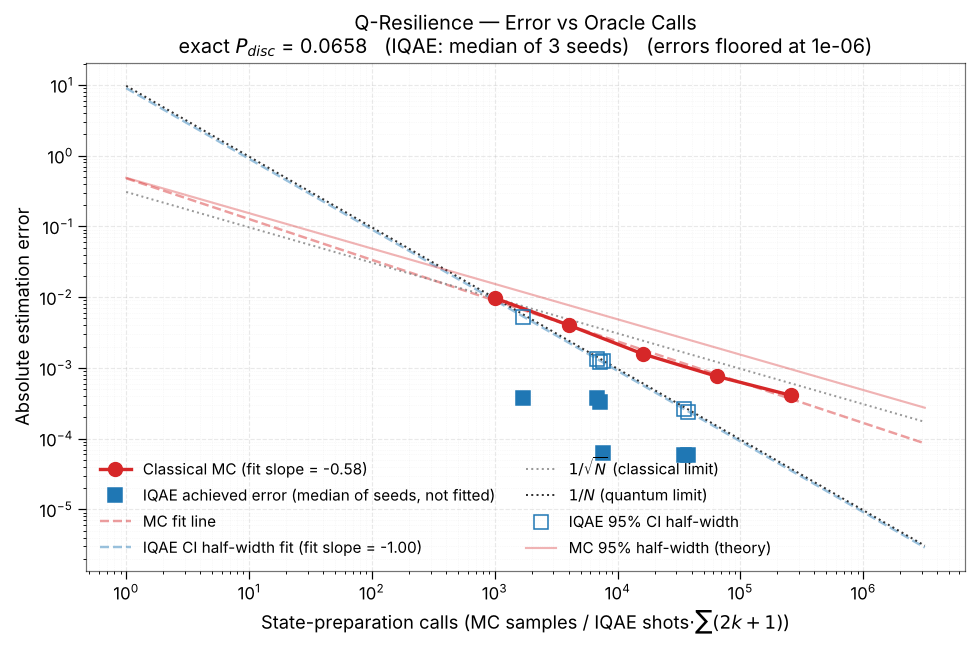

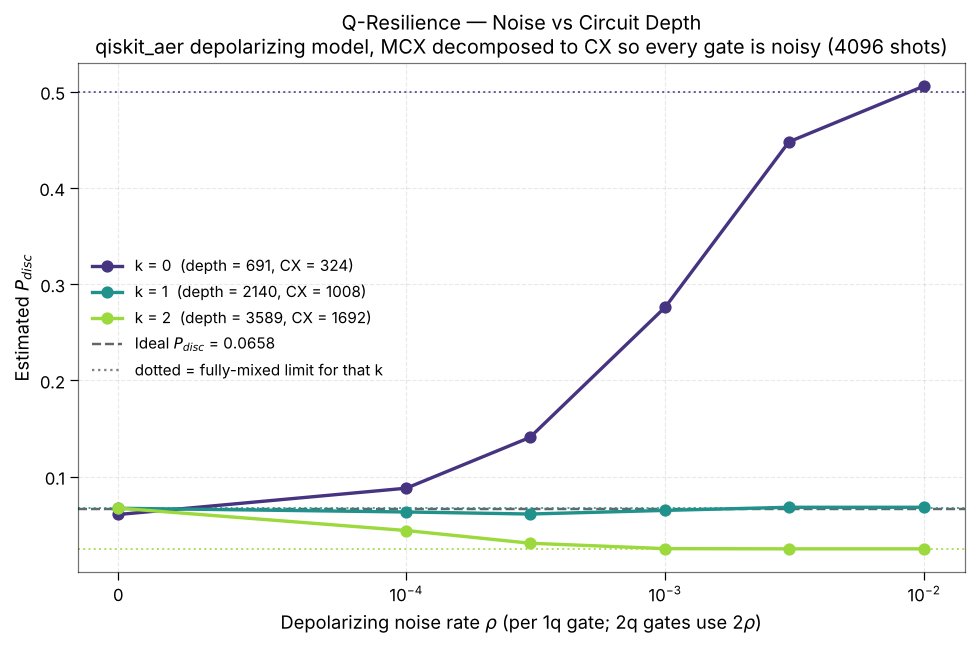


Building resource-scaling grids …
[2x2] nodes= 4  edges= 4  qubits= 5  gates=    37  depth=   23  built in 0.00s
[2x3] nodes= 6  edges= 7  qubits= 8  gates=   609  depth=  257  built in 0.01s
[2x4] nodes= 8  edges=10  qubits=11  gates=  8150  depth= 2414  built in 0.08s


[3x3] nodes= 9  edges=12  qubits=13  gates= 34869  depth= 8871  built in 0.33s


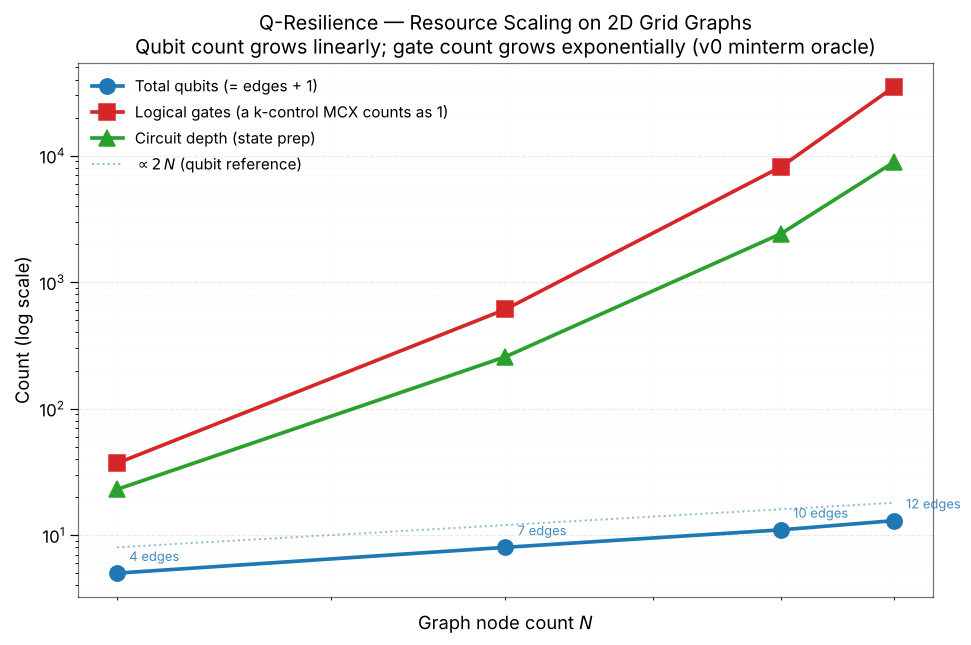


[added] v0 vs v1 resource comparison …
grid   links  v0 masks  v0 qubits  v0 Toffoli  v1 qubits  v1 Toffoli
2x2        4         9          5          45          9           6
2x3        7        88          8         968         33          39
2x4       10       808         11      13,736         71         106
3x3       12     2,961         13      62,181        117         192
3x4       17   skipped         18         2^m        254         454


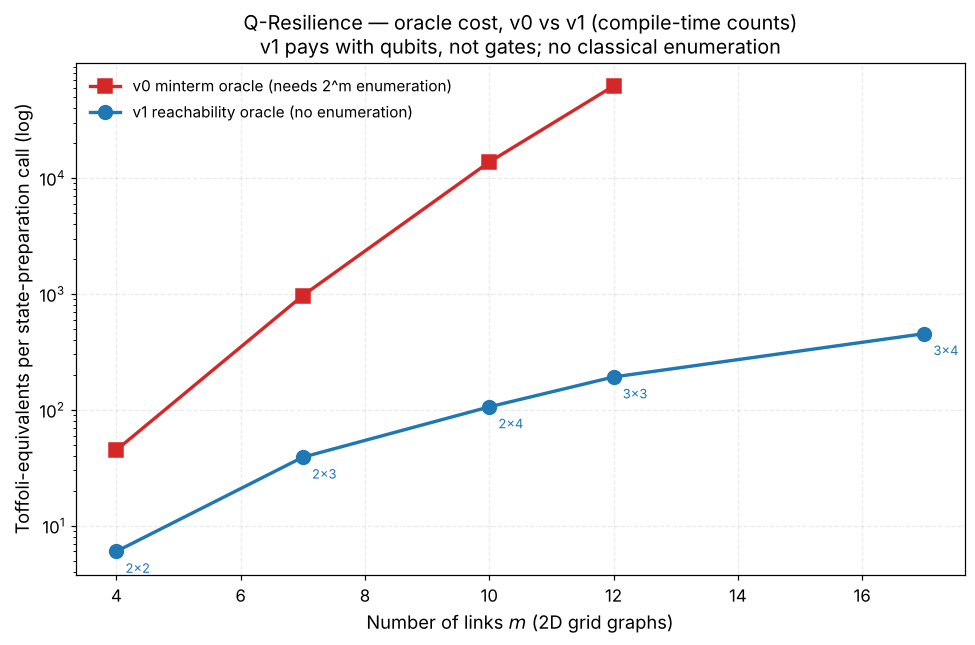


Figures saved:
  • qresilience_error_vs_oracle.png
  • qresilience_noise_vs_depth.png
  • qresilience_resource_scaling.png
  • qresilience_v0_vs_v1.png


In [16]:
# %% [Cell 12] — Render all three hackathon figures
print("=" * 62)
print("Generating Q-Resilience analysis plots …")
print("=" * 62)

fig1 = plot_error_vs_oracle_calls()          # uses NETWORK / FAILURE_PROBS / config

try:
    fig2 = plot_noise_vs_circuit_depth()     # uses config; qiskit-aer required
except RuntimeError as exc:
    fig2 = None
    print(f"\n[SKIPPED] Plot 2: {exc}")

print("\nBuilding resource-scaling grids …")
fig3 = plot_resource_scaling()

print("\nGenerating v0 vs v1 resource comparison …")
fig4 = plot_v0_vs_v1_resources()

print("\nFigures saved:")
print(f"  • {PATH_FIG1}")
if fig2 is not None:
    print(f"  • {PATH_FIG2}")
print(f"  • {PATH_FIG3}")
print(f"  • {PATH_FIG4}")

## Limitations and interpretation

- **Failure model.** Edge failures are independent. In practical networks, failures may be correlated by shared infrastructure, weather, or other common causes; those dependencies are not represented here.
- **Validation range.** IQAE agrees with exact enumeration for the configured network. The v0 and v1 oracles are cross-checked on the cases in Cell 7c, whose sizes are limited to roughly 22 qubits so that statevector simulation is feasible. The larger v1 cases in Figure 4 are compile-time counts and were not simulated.
- **Meaning of the query comparison.** The potential advantage of amplitude estimation concerns the number of state-preparation calls required for a target precision. A call represents execution of a circuit, not a unit of wall-clock time. Circuit depth, compilation overhead, measurement, and noise all affect practical cost.
- **Oracle resources.** Constructing v0 requires classical enumeration of up to $2^m$ failure masks. The v1 construction avoids that enumeration but retains intermediate values, increasing its qubit requirement. Its Toffoli-equivalent counts use the cost model described in Cell 7b.
- **Figure 1.** The achieved-error curve is based on a finite set of runs and seeds; its fitted slope is descriptive. The confidence-interval half-width gives the more direct measure of the estimator's stated uncertainty.
- **Related work.** Quantum amplitude estimation has been studied for network and power-system reliability, including reachability-operator constructions (arXiv:2203.10201). This notebook presents a Qiskit implementation with cross-validation, resource estimates, and a noise study; it does not propose a new amplitude-estimation algorithm.